# **TRABAJO PRACTICO ESPECIAL** 

## **IMPORTS DE LIBRERIAS**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import statsmodels.api as sm

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Importamos las librerias correspondientes para trabajar la base

## APERTURA Y ANALISIS DE LA BASE

In [2]:
# Si está en la misma carpeta que la notebook:
df = pd.read_csv('CKD_NHANES_2021_2023.csv')
df

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,...,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,...,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,...,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,...,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,...,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11928,142306.0,9.0,Male,Other Hispanic,NaN,2.01,15.4,25.3,128.0,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
11929,142307.0,49.0,Female,Non-Hispanic Black,5.0,NaN,NaN,NaN,143.8,127.0,...,6.31,6.78,1.0,2.0,1.0,1.0,3.0,91.64,No CKD,0
11930,142308.0,50.0,Male,Other Hispanic,4.0,1.95,26.4,79.3,173.3,106.0,...,6.98,4.03,2.0,NaN,NaN,2.0,NaN,NaN,Unknown,1
11931,142309.0,40.0,Male,Other Hispanic,4.0,3.11,25.5,81.9,179.1,127.0,...,9.27,3.65,2.0,NaN,NaN,2.0,NaN,92.03,No CKD,0


In [3]:
#Analizamos el dataset, imprimimos su info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  str    
 3   ethnicity                 11933 non-null  str    
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosphorus       

Aca ya imprimimos las 29 columnas del dataset, donde podemos ver tambien el tipo de cada columna.
Y tambien hacemos un describe() para obtener informacion de cada columna.

In [4]:
df.describe()

,participant_id,age,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,...,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_present
count,11933.000000,1.193300e+04,7794.000000,9.892000e+03,8471.000000,8754.000000,8499.000000,7517.000000,7517.000000,6326.000000,...,8154.000000,8153.000000,8153.000000,11740.000000,1081.000000,2281.000000,8135.000000,3243.000000,6326.000000,11933.000000
mean,136344.000000,3.831786e+01,3.804978,2.708174e+00,27.246665,70.549037,159.664549,119.288546,72.748038,0.872828,...,133.258646,35.567928,33.355533,1.934497,1.681776,1.633494,1.611678,2.339500,96.599750,0.698986
std,3444.904716,2.560199e+01,1.153750,1.670119e+00,8.137781,30.389021,19.864943,18.561052,11.895572,0.385498,...,90.676053,175.582217,251.094041,0.358726,0.466002,0.635776,0.558182,0.900889,24.633731,0.458718
min,130378.000000,5.397605e-79,1.000000,5.397605e-79,11.100000,2.700000,79.100000,61.000000,33.000000,0.330000,...,4.000000,0.210000,0.080000,1.000000,1.000000,1.000000,1.000000,1.000000,3.510000,0.000000
25%,133361.000000,1.300000e+01,3.000000,1.180000e+00,21.600000,54.200000,154.400000,106.000000,64.000000,0.700000,...,65.000000,5.770000,5.420000,2.000000,1.000000,1.000000,1.000000,1.000000,80.502500,0.000000
50%,136344.000000,3.700000e+01,4.000000,2.500000e+00,26.400000,71.700000,163.600000,117.000000,72.000000,0.830000,...,117.000000,9.620000,8.270000,2.000000,2.000000,2.000000,2.000000,3.000000,97.030000,1.000000
75%,139327.000000,6.200000e+01,5.000000,4.500000e+00,31.700000,89.100000,172.100000,130.000000,80.000000,0.980000,...,181.000000,17.830000,15.330000,2.000000,2.000000,2.000000,2.000000,3.000000,112.660000,1.000000
max,142310.000000,8.000000e+01,9.000000,5.000000e+00,74.800000,248.200000,200.700000,232.000000,142.000000,15.170000,...,873.000000,7942.470000,14708.280000,9.000000,2.000000,9.000000,9.000000,3.000000,178.430000,1.000000


# ANALISIS EXPLORATORIO DE DATOS

Ahora pasamos a contar la cantidad de filas repetidas que hay en el dataset

In [5]:
df.duplicated().sum()

np.int64(0)

Vemos que no hay ninguna fila repetida, debido a que participant_id es un valor unico de cada persona.
Ahora vamos a contar cuantos nulos hay por cada columna, y agregamos una columna con el porcentaje de estos.

In [6]:
# Conteo y porcentaje de valores faltantes por variable
nulos = pd.DataFrame({
    'nulos': df.isnull().sum(),
    'porcentaje': (df.isnull().mean() * 100).round(2),
}).sort_values(by='porcentaje', ascending=False)

print(nulos)

                          nulos  porcentaje
insulin_use               10852       90.94
diabetes_pills             9652       80.88
current_smoker             8690       72.82
phosphorus                 5611       47.02
bicarbonate                5608       47.00
blood_urea_nitrogen        5607       46.99
serum_creatinine           5607       46.99
egfr                       5607       46.99
uric_acid                  5604       46.96
calcium                    5571       46.69
albumin_serum              5567       46.65
bp_diastolic               4416       37.01
bp_systolic                4416       37.01
education_level            4139       34.69
ever_smoked                3798       31.83
urine_albumin              3780       31.68
albumin_creatinine_ratio   3780       31.68
urine_creatinine           3779       31.67
bmi                        3462       29.01
height_cm                  3434       28.78
weight_kg                  3179       26.64
poverty_income_ratio       2041 

## ANALISIS DE LOS NULOS

Podemos ver que la columna con mas nulos es **insuline_use**, y esto se debe a que solo respondieron la pregunta sobre el uso de insulina, los pacientes a los que un profesional les diagnosticó diabetes. 1 es que usa insulina, 2 es que no.

Con las columnas relacionadas a los **analisis de sangre** lo que pasó es que se analizó a personas mayores de 12 años, aunque tambien hay algunos analisis faltantes más de personas que no fueron al examen(faltan todos sus datos de sangre). Y hay otros(62 personas) que tienen solo algunos datos de la sangre

Lo mismo pasó con la **presion arterial**, **bp_systolic y bp_diastolic** solo se midieron paraa personas mayores de 8 años(y tambien hay algunos que no asistieron, pero siempre faltan ambas columnas). 

Con las columnas de **orina** **(urine_albumin, urine_creatinine, albumin_creatinine_ratio)** tambien faltan muestras, faltan juntas. 

Para las columnas **education_level y ever_smoked**, solo vamos a filtrar para quedarnos con los **adultos mayores a 20 años**, luego de eso tendremos unos 26 y 29 nulos respectivamente, lo cual representa menos del 0,5% de los datos, por lo que podemos descartar esas filas cuando usemos la columna.

Con respecto a los nulos en las medidas corporales(bmi, height_cm, weight_kg), lo que intentamos hacer es, si tenemos 2 de las 3 medidas, calular la faltante, ya que bmi es un calculo entre height_cm y weight_kg. Pero, no hay ningun caso en el dataset donde tengamos 2 medidas y falte 1.

falta decidir que hacer con poverty_income_ratio y con ckd_stage(y ckd_present) por el tema del unknown

Tambien, pasamos a NaN a los valores 7 y 9 de las columnas indicadas ya que estos codigos representan "Se negó a responder / no sabe"

In [7]:
cols_cuestionario = [c for c in ['diabetes_diagnosed', 'ever_smoked', 'education_level', 'diabetes_pills'] if c in df.columns]

for col in cols_cuestionario:
    # 7 y 9 son valores no informativos en NHANES -> los pasamos a NaN
    df[col] = df[col].replace({7: np.nan, 9: np.nan})

In [8]:
#pasamos a 0 las edades que son numeros cercanos a 0
df.loc[df['age'] < 1e-10, 'age'] = 0

In [9]:
#filtramos por edad y vemos la cantidad de nulos de las dos columnas mencionadas antes
#mayores de 12(analisis de sangre)
sangre = ["phosphorus", "bicarbonate", "blood_urea_nitrogen", "serum_creatinine",
          "egfr", "uric_acid", "calcium", "albumin_serum"]

df_sangre = df[df['age'] >= 12]
faltantes = df_sangre[sangre].isna().sum(axis=1)      
# cuántos de los 8 le faltan a cada persona

print("Personas de mayores de 12:", len(df_sangre))
print(faltantes.value_counts().sort_index())
print("Les faltan los 8:", (faltantes == 8).sum())
print("Les faltan algunos, pero no todos:", ((faltantes > 0) & (faltantes < 8)).sum())

Personas de mayores de 12: 9388
0    6304
1      19
2       2
3       2
4       2
5      13
6      24
8    3022
Name: count, dtype: int64
Les faltan los 8: 3022
Les faltan algunos, pero no todos: 62


In [10]:
presion = ["bp_systolic", "bp_diastolic"]
df_presion = df[df['age'] >= 8]
print(df_presion['bp_systolic'].isnull().sum())
print(df_presion['bp_diastolic'].isnull().sum())
faltantes_presion = df_presion[presion].isna().sum(axis=1)

print("Personas de mayores de 8:", len(df_presion))
print("Les faltan los 2:", (faltantes_presion == 2).sum())
print("Les faltan algunos, pero no todos:", ((faltantes_presion > 0) & (faltantes_presion < 2)).sum())

2770
2770
Personas de mayores de 8: 10287
Les faltan los 2: 2770
Les faltan algunos, pero no todos: 0


In [11]:
#mayores de 20
df_filtrado_mayores = df[df['age'] >= 20]
print(df_filtrado_mayores['education_level'].isnull().sum())
print(df_filtrado_mayores['ever_smoked'].isnull().sum())

26
29


In [12]:
#notna() detecta los válidos o existentes, devuelve True para los datos presentes y False para los valores nulos
#habiamos intentado calcular los datos faltantes a partir de 2 valores, pero no hay ninguna fila que tenga 2 valores como para calcular el otro
medidas = ["bmi", "weight_kg", "height_cm"]
cantidad = df[medidas].notna().sum(axis=1)

print(cantidad.value_counts().sort_index())
print("Filas con  2 medidas:", (cantidad == 2).sum())

0    3151
1     311
3    8471
Name: count, dtype: int64
Filas con  2 medidas: 0


In [13]:
# hay casos que tienen eGFR mayor a 90 pero tienen el ACR en nulo, y en ckd_stage tienen como valor NO_CKD(esto segun la informacion
# que tenemos es cuando el eGFR es mayor o igual a 90 y el ACR es menor a 30). Al no tener valor de ACR este dato es inconsistente, y como
# tenemos 70 casos de este tipo(que tienen eGFR mayor o igual a 90 y ACR menor a 30) lo cual es un 1,76% de los 3974 datos, 
# podemos descartar estas filas.

inconsistencia_ckd = df['albumin_creatinine_ratio'].isna() & (df['egfr'] >= 90)

# Filtramos el DataFrame conservando todo lo opuesto (el símbolo ~ niega la condición)
df= df[~inconsistencia_ckd].copy()

In [14]:
filtro_unknown = df['ckd_stage'] == 'Unknown'

# Ponemos nulo en ckd_stage y ckd_present para esas filas donde es unknown
df.loc[filtro_unknown, 'ckd_present'] = np.nan
df.loc[filtro_unknown, 'ckd_stage'] = np.nan
df

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,...,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,...,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0.0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,...,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0.0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,...,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0.0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,...,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11928,142306.0,9.0,Male,Other Hispanic,NaN,2.01,15.4,25.3,128.0,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11929,142307.0,49.0,Female,Non-Hispanic Black,5.0,NaN,NaN,NaN,143.8,127.0,...,6.31,6.78,1.0,2.0,1.0,1.0,3.0,91.64,No CKD,0.0
11930,142308.0,50.0,Male,Other Hispanic,4.0,1.95,26.4,79.3,173.3,106.0,...,6.98,4.03,2.0,NaN,NaN,2.0,NaN,NaN,NaN,NaN
11931,142309.0,40.0,Male,Other Hispanic,4.0,3.11,25.5,81.9,179.1,127.0,...,9.27,3.65,2.0,NaN,NaN,2.0,NaN,92.03,No CKD,0.0


# **Hipótesis y resolución**
Vamos a analizar 6 hipotesis, una univariada, tres bivariadas y dos multivariadas.

## UNIVARIADAS

## Hipotesis univariada 1: “Predomina el sobrepeso en la muestra”

En la metadata se menciona el **exceso de peso** entre los factores relacionados con el **deterioro renal**.
Que **“predomine”** lo tomamos como que las categorías **sobrepeso** y **obesidad** son más frecuentes y significativamentes mayores que las otras.

En caso de probarse, se podrián tomar **medidas para concientizar** sobre el exceso de peso y sus consecuencias. Y aunque el analisis es sobre adultos, las medidas pueden llevarse a todas las edades, para que los mas jovenes no lleguen a una situacion de exceso de peso que **afecte su salud** a largo plazo.

In [15]:
# para este analisis solo vamos a usar a los adultos del dataset
# filtramos solo la población adulta (>= 18 años) para usar los cortes estándar 
# de Indice de Masa Corporal (BMI como aparece en nuestro dataset)
df_adultos = df[df['age'] >= 18].copy()

# Ver cuántos adultos no tenían registro de bmi
nulos_bmi = df_adultos['bmi'].isna().sum()
print(f"Adultos excluidos por falta de datos de bmi: {nulos_bmi}")


# Definimos los límites de las categorías de la OMS para el bmi
limites = [0, 18.5, 25, 30, float('inf')]
labels = ['Bajo peso', 'Normopeso', 'Sobrepeso', 'Obesidad']

# en df_adultos creamos una nueva columna categórica con el estado nutricional
df_adultos['estado_nutricional'] = pd.cut(df_adultos['bmi'], bins=limites, labels=labels, right=False)

# Calculamos frecuencias y porcentajes
conteo_imc = df_adultos['estado_nutricional'].value_counts()
porcentajes_imc = df_adultos['estado_nutricional'].value_counts(normalize=True) * 100

print("Frecuencias")
print(conteo_imc)
print("\n Porcentajes %")
print(porcentajes_imc.round(2))


Adultos excluidos por falta de datos de bmi: 1904
Frecuencias
estado_nutricional
Obesidad     2511
Sobrepeso    1946
Normopeso    1633
Bajo peso     107
Name: count, dtype: int64

 Porcentajes %
estado_nutricional
Obesidad     40.52
Sobrepeso    31.40
Normopeso    26.35
Bajo peso     1.73
Name: proportion, dtype: float64


Ahora podemos generar los **graficos** para hacer la comparación

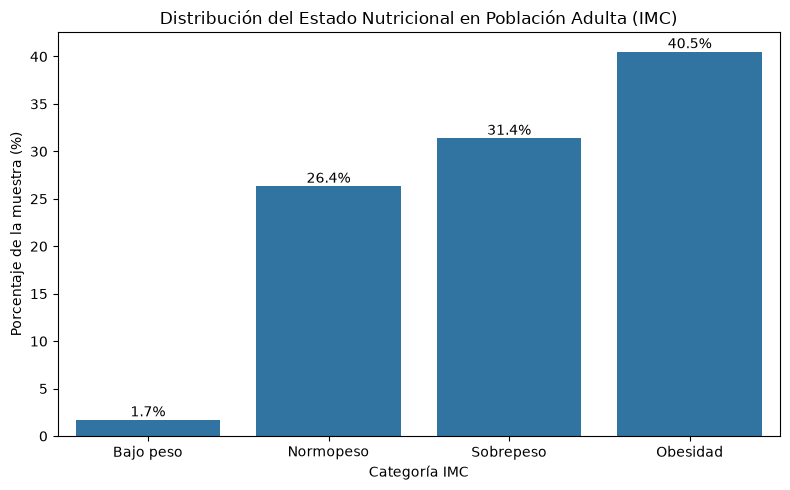

In [16]:
# gráfico de distribución
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=porcentajes_imc.index, y=porcentajes_imc.values)
plt.title('Distribución del Estado Nutricional en Población Adulta (IMC)')
plt.xlabel('Categoría IMC')
plt.ylabel('Porcentaje de la muestra (%)')

# Añade los valores numéricos arriba de las barras
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

### Resultados
Mediante el grafico podemos concluir que **nuestra hipotesis se cumple**, ya que hay un **40,5%** de personas con **obesidad** y un **31,5%** de personas con **sobrepeso**. Ambas categorias se estudian como **"Exceso de Peso"** el cual es un factor relacionado con el deterioro renal.

### Aclaraciones: 
cuando bmi es NaN, la nueva columna tambien tiene NaN. 
Ademas value_counts() ignora y descarta automáticamente todos los valores nulos.
Por esto mismo, aclaramos cuantos adultos fueron excluidos por no tener ibm.

## BIVARIADAS

## HIPOTESIS BIVARIADA 1: "La proporción de personas con diagnóstico positivo de diabetes (diabetes_diagnosed) es significativamente mayor en los estratos de menor nivel de ingresos (medido a través del poverty_income_ratio)."

### Variables implicadas:
**diabetes_diagnosed** (Categórica): 1 = Sí, 2 = No, 3 = Diagnóstico límite o Borderline

**poverty_income_ratio** (Cuantitativa continua): Ratio entre el ingreso familiar y la línea de pobreza, donde 0 indica ingresos muy bajos y 5 el límite superior agrupado.

Planteo de Hipótesis:
$H_0$ (Hipótesis Nula): La proporción de diagnósticos positivos de diabetes es independiente del nivel de ingresos (o no hay diferencia significativa en el ratio de pobreza entre personas con y sin diabetes).

$H_1$ (Hipótesis Alternativa): La proporción de diabetes es significativamente mayor en estratos de menores ingresos (los ingresos son significativamente menores en el grupo diagnosticado con diabetes).

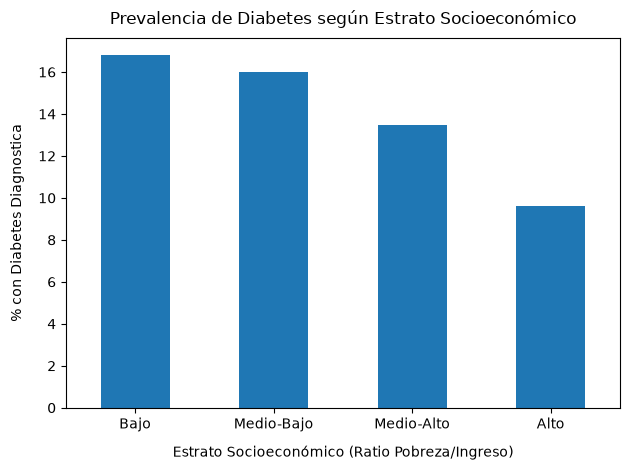

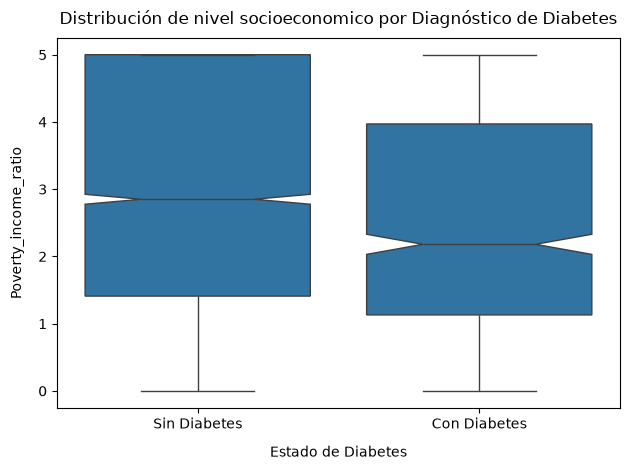

In [17]:
h_b1 = df[df["age"] >= 18].copy()
# filtramos por edad y graficamos para ver la distribucion

# Eliminamos las filas que tengan nulos en las variables del análisis
h_b1 = h_b1.dropna(
    subset=["diabetes_diagnosed", "poverty_income_ratio"]
).copy()

h_b1["diabetes"] = (h_b1["diabetes_diagnosed"] == 1).astype(int)

# Discretizamos la variable de "poverty_income_ratio" en 4 categorias
h_b1["estrato"] = pd.cut(
    h_b1["poverty_income_ratio"],
    [0, 1, 2, 4, 5.01],
    right=False,
    labels=["Bajo", "Medio-Bajo", "Medio-Alto", "Alto"],
    include_lowest=True,
)

# Gráfico de Barras: Prevalencia de Diabetes por Nivel Socioeconómico
prev = h_b1.groupby("estrato", observed=True)["diabetes"].mean() * 100
ax1 = prev.plot.bar()
plt.title("Prevalencia de Diabetes según Estrato Socioeconómico", fontsize=12, pad=10)
plt.xlabel("Estrato Socioeconómico (Ratio Pobreza/Ingreso)", labelpad=10)
plt.ylabel("% con Diabetes Diagnostica", labelpad=10)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Boxplot, distribución de ingresos según diagnóstico
ax2 = sns.boxplot(data=h_b1, x="diabetes", y="poverty_income_ratio", notch=True)
plt.title("Distribución de nivel socioeconomico por Diagnóstico de Diabetes", fontsize=12, pad=10)
plt.xlabel("Estado de Diabetes", labelpad=10)
plt.ylabel("Poverty_income_ratio", labelpad=10)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(["Sin Diabetes", "Con Diabetes"])
plt.tight_layout()
plt.show()



In [18]:
# Al tener 2 variables categoricas(ya que discretizamos poverty_income_ratio)
#Creamos la tabla de contingencia con frecuencias observadas
tabla = pd.crosstab(h_b1["estrato"], h_b1["diabetes"])
chi2, p, gl, esperados = stats.chi2_contingency(tabla)
print(f"\n--- RESULTADOS DEL TEST DE CHI-CUADRADO ---")
print(f"Estadístico Chi2: {chi2:.4f}")
#imprimimos el p-valor
print(f"p-valor: {p:.4e}")
## definimos el nivel de significancia en 0,05
alpha = 0.05 
if p < alpha: 
    print(f"\n-- Decisión: Se rechaza la hipotesis nula H0 (p-valor < {alpha}).") 
    print("Existe una asociación estadísticamente significativa entre el estrato de ingresos y la prevalencia de diabetes.")
else: 
    print(f"\n-- Decisión: No se rechaza H0 (p-valor >= {alpha}).") 
    print("No hay evidencia suficiente para afirmar una asociación entre el estrato de ingresos y el diagnostico de diabetes.")



--- RESULTADOS DEL TEST DE CHI-CUADRADO ---
Estadístico Chi2: 48.1212
p-valor: 2.0067e-10

-- Decisión: Se rechaza la hipotesis nula H0 (p-valor < 0.05).
Existe una asociación estadísticamente significativa entre el estrato de ingresos y la prevalencia de diabetes.


### Resultados
Mirando los graficos dados se observa un **decrecimiento** en la prevalencia de diabetes a medida que **aumenta** el estrato de ingresos (pasando de un mayor porcentaje en el estrato `Bajo` a un menor porcentaje en el estrato `Alto`). Ademas, el gráfico de boxplot muestra que la **mediana** del ratio de pobreza es inferior en el grupo con **diagnóstico de diabetes**.

La prueba de **Chi-cuadrado** de Independencia arrojó un estadístico significativo con un $p$-valor < 0,05

**Decidimos** rechazar la hipótesis nula ($H_0$). Existe evidencia estadística suficiente para afirmar que la proporción de personas diagnosticadas con diabetes es significativamente mayor en los estratos de menores ingresos socioeconómicos. Con esta informacion, se podrian tomar medidas en la salud publica para concientizar sobre los riesgos de la diabetes e incentivar a una mejor alimentacion aunque los recursos sean escasos. 


# HIPOTESIS BIVARIADA 2: "La mayoría de los casos de CKF identificados corresponde a blancos no-hispánicos."

=== TABLA RESUMEN POR ETNIA ===

                     casos  % de los casos  n muestra  % de la muestra  \
ethnicity                                                               
Non-Hispanic White   1741            63.7       6184             52.1   
Non-Hispanic Black    377            13.8       1588             13.4   
Other Hispanic        235             8.6       1365             11.5   
Other/Multiracial     169             6.2        940              7.9   
Mexican American      118             4.3       1110              9.4   
Non-Hispanic Asian     94             3.4        676              5.7   

                    prevalencia CKD %  
ethnicity                              
Non-Hispanic White               28.2  
Non-Hispanic Black               23.7  
Other Hispanic                   17.2  
Other/Multiracial                18.0  
Mexican American                 10.6  
Non-Hispanic Asian               13.9  
#############


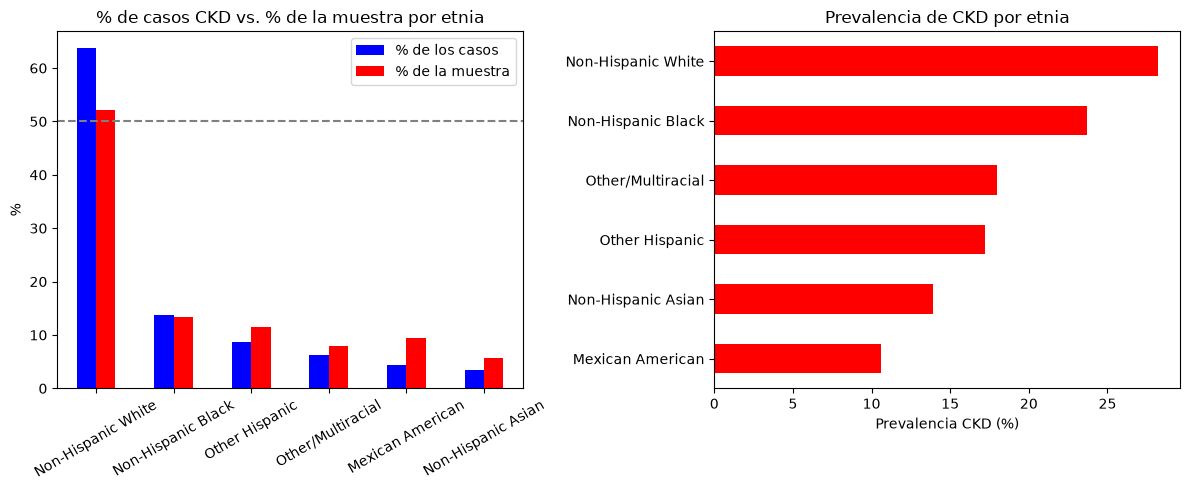

In [19]:
casos = df[df["ckd_present"] == 1]
cc = casos["ethnicity"].value_counts()
cm = df["ethnicity"].value_counts()
tabla = pd.DataFrame({
    "casos": cc,
    "% de los casos": (cc / cc.sum() * 100).round(1),
    "n muestra": cm, #cuantas personas hay de esa etnia
    "% de la muestra": (cm / cm.sum() * 100).round(1),
    "prevalencia CKD %": (cc / cm * 100).round(1),
}).sort_values("casos", ascending=False)

print("=== TABLA RESUMEN POR ETNIA ===")
print("\n", tabla)
print("#############")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
# Comparativa de porcentajes
tabla[["% de los casos", "% de la muestra"]].plot.bar(ax=ax[0], color=["#0000ff", "#FF0000"])
ax[0].axhline(50, ls="--", c="gray")
ax[0].set_title("% de casos CKD vs. % de la muestra por etnia")
ax[0].set_ylabel("%")
ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=30)

# Prevalencia por etnia
tabla["prevalencia CKD %"].sort_values().plot.barh(ax=ax[1], color="#FF0000")
ax[1].set_title("Prevalencia de CKD por etnia")
ax[1].set_xlabel("Prevalencia CKD (%)")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [20]:
#Para validar la hipotesis vamos a usar Chi-cuadrado
# Para dos variables cualitativas/categóricas (como ethnicity y ckd_present), 
# la herramienta oficial y no paramétrica del programa es la Prueba Chi-cuadrado de independencia

#  Tabla de contingencia observada (Etnia vs Presencia de CKD) 
tabla_contingencia = pd.crosstab(df["ethnicity"], df["ckd_present"]) 
# Test Chi-cuadrado de independencia
chi2, p_valor, gl, esperados = stats.chi2_contingency(tabla_contingencia) 
print(f"Estadístico Chi2: {chi2:.4f}")
print(f"Grados de libertad: {gl}") 
print(f"p-valor: {p_valor:.4e}") 
# Decisión estadística 
if p_valor < 0.05: 
    print( "Se rechaza H0: Existe una asociación estadísticamente significativa entre la etnia y la presencia de CKD." ) 
    print( "Se confirma que Non-Hispanic White tiene una diferencia significativa de prevalencia de CKD (donde lidera con el 28.0%)." )
else: 
    print("No hay evidencia suficiente para afirmar una asociación entre la etnia y la presencia de CKD.")

Estadístico Chi2: 198.8623
Grados de libertad: 5
p-valor: 4.9750e-41
Se rechaza H0: Existe una asociación estadísticamente significativa entre la etnia y la presencia de CKD.
Se confirma que Non-Hispanic White tiene una diferencia significativa de prevalencia de CKD (donde lidera con el 28.0%).


### **Resultados**
El grupo de Blancos No-Hispánicos no solo tiene la mayor cantidad de casos absolutos porque representa el 52.1% de la muestra general, sino que **también es la etnia con la tasa de prevalencia más alta de toda la muestra (28.2%)**.

---

## HIPOTESIS BIVARIADA 3: "La presión arterial es un factor de riesgo del CKF"


**Variables que usamos del dataset:**
**bp_systolic** (Cuantitativa continua): Presión arterial sistólica medida en mmHg, el indicador de presión máxima durante la contracción cardíaca.

**ckd_present** (Categórica binaria): Indicador de presencia de enfermedad renal crónica (0 = Sin CKD, 1 = Con CKD).

**Formulación de Hipótesis:**
$H_0$ (Hipótesis Nula): La presión arterial sistólica no difiere entre personas con y sin CKD (los niveles de presión arterial son independientes del diagnóstico de enfermedad renal).
$H_1$ (Hipótesis Alternativa): La presión arterial sistólica es significativamente mayor en personas con diagnóstico positivo de CKD

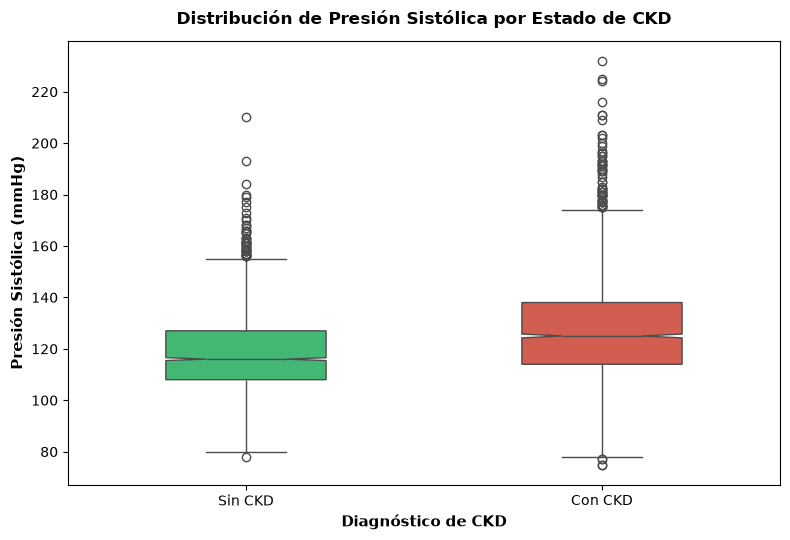

In [21]:
# Preparación de datos y filtrado
h_bp = df[df["age"] >= 18].copy()
h_bp = h_bp.dropna(subset=["bp_systolic", "ckd_present"]).copy()
h_bp["ckd_label"] = h_bp["ckd_present"].map({0: "Sin CKD", 1: "Con CKD"})

fig, ax = plt.subplots(figsize=(8, 5.5))

# Gráfico A: Boxplot comparativo (ahora se usa "ax" en lugar de "ax[0]")
sns.boxplot(
    data=h_bp,
    x="ckd_label",
    y="bp_systolic",
    hue="ckd_label",
    notch=True,
    palette=["#2ecc71", "#e74c3c"],
    width=0.45,
    legend=False,
    ax=ax,
)
ax.set_title(
    "Distribución de Presión Sistólica por Estado de CKD",
    fontsize=12,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("Diagnóstico de CKD", fontsize=11, fontweight="bold")
ax.set_ylabel("Presión Sistólica (mmHg)", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

Qué Test usamos? En este caso vamos a usar el test U de Mann-Whitney, ya que chequeamos que no se cumple el supuesto de normalidad, por lo que no podemos usar el test parametrico t de student.

El test U de Mann-Whitney se utiliza al violarse el supuesto de normalidad o ante la presencia de valores atípicos (*outliers*). Es la prueba libre de distribución para comparar 2 grupos independientes.

El chequeo de normalidad se hace con la prueba de Shapiro-Wilk

In [22]:
# Chequeo el supuesto de normalidad con la Prueba de Shapiro-Wilk
bp_sin = h_bp[h_bp["ckd_present"] == 0]["bp_systolic"]
bp_con = h_bp[h_bp["ckd_present"] == 1]["bp_systolic"]

_, p_norm_sin = stats.shapiro(
    bp_sin.sample(min(500, len(bp_sin)), random_state=42)
)
_, p_norm_con = stats.shapiro(
    bp_con.sample(min(500, len(bp_con)), random_state=42)
)

print("\n CHEQUEO DE NORMALIDAD (SHAPIRO-WILK)")
print(f"Grupo Sin CKD: p-valor = {p_norm_sin:.4e}")
print(f"Grupo Con CKD: p-valor = {p_norm_con:.4e}")

# Selección del Test Estadístico e Inferencia
alpha = 0.05
if p_norm_sin < alpha or p_norm_con < alpha:
    print(
        "\n-> Violación del supuesto de normalidad (p < 0.05). Se aplica el test"
        " NO PARAMÉTRICO U de Mann-Whitney."
    )
    stat_test, p_valor = stats.mannwhitneyu(
        bp_con, bp_sin, alternative="greater"
    )
    nombre_test = "U de Mann-Whitney"
else:
    print(
        "\n-> Se cumple la normalidad. Se aplica el TEST T PARAMÉTRICO de"
        " Student."
    )
    stat_test, p_valor = stats.ttest_ind(bp_con, bp_sin, alternative="greater")
    nombre_test = "t de Student para muestras independientes"

print(f"\n RESULTADO DE LA PRUEBA ESTADÍSTICA ({nombre_test})")
print(f"Estadístico de prueba: {stat_test:.4f}")
print(f"p-valor: {p_valor:.4e}")

if p_valor < alpha:
    print(f"\nDecisión: Se rechaza H0 (p-valor < {alpha}).")
    print(
        "Conclusión: La presión arterial sistólica es significativamente mayor"
        " en el grupo con diagnóstico de CKD."
    )
else:
    print(f"\nDecisión: No se rechaza H0 (p-valor >= {alpha}).")
    print(
        "Conclusión: No hay evidencia suficiente para afirmar que la presión"
        " arterial difiera entre los grupos, por lo que no podemos afirmar la"
        "hipotesis de que La presión arterial es un factor de riesgo del CKF"
    )


 CHEQUEO DE NORMALIDAD (SHAPIRO-WILK)
Grupo Sin CKD: p-valor = 1.7441e-05
Grupo Con CKD: p-valor = 6.5567e-08

-> Violación del supuesto de normalidad (p < 0.05). Se aplica el test NO PARAMÉTRICO U de Mann-Whitney.

 RESULTADO DE LA PRUEBA ESTADÍSTICA (U de Mann-Whitney)
Estadístico de prueba: 4775966.0000
p-valor: 3.1088e-76

Decisión: Se rechaza H0 (p-valor < 0.05).
Conclusión: La presión arterial sistólica es significativamente mayor en el grupo con diagnóstico de CKD.


### Conclusion:
La **hipertensión** sostenida produce una sobrecarga mecánica en los glomérulos renales, acelerando el deterioro de la función de filtrado.

Al **rechazar** la hipótesis nula ($p < 0.05$), los datos confirman empíricamente que la hipertensión constituye un **factor de riesgo** asociado de forma significativa con la **enfermedad renal crónica**.

---

## HIPOTESIS MULTIVARIADAS

## Hipotesis Multivariada 1. "Existe un vínculo directo entre la edad, sexo, BMI, presión arterial, diabetes, tabaquismo y nivel socioeconómico con la probabilidad de presentar CKD."

**Existe un vínculo directo entre la edad, sexo, BMI, presión arterial, diabetes,
tabaquismo y nivel socioeconómico con la probabilidad de presentar CKD.**

Para analizar esta hipotesis el método estadístico que vamos a usar es la **Regresión Logística Multivariada**
Esto lo hacemos asi ya que la variable objetivo es binaria/dicotomica (ckd_present: $0 = \text{Sin CKD}$, $1 = \text{Con CKD}$)

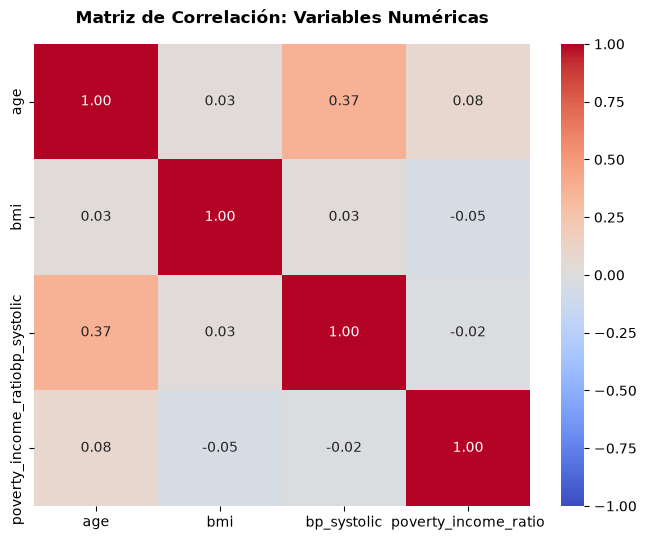


 REVISIÓN DE MULTICOLINEALIDAD 
Regla: Si hay valores > 0.7 o < -0.7, esas variables están muy correlacionadas y podría ser un problema.
Optimization terminated successfully.
         Current function value: 0.534081
         Iterations 6

 RESUMEN DEL MODELO DE REGRESIÓN LOGÍSTICA
                           Logit Regression Results                           
Dep. Variable:            ckd_present   No. Observations:                 4717
Model:                          Logit   Df Residuals:                     4708
Method:                           MLE   Df Model:                            8
Date:                Sun, 08 Nov 2026   Pseudo R-squ.:                  0.2276
Time:                        14:35:03   Log-Likelihood:                -2519.3
converged:                       True   LL-Null:                       -3261.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      

In [23]:
# Tomamos las variables de interés para la hipótesis
columnas_analisis = [
    "ckd_present",          # Variable objetivo
    "age",
    "bmi",
    "bp_systolic",
    "poverty_income_ratio",
    "gender",
    "diabetes_diagnosed",
    "ever_smoked"
]

# Nos quedamos con las columnas y eliminamos nulos
df_multi = df[columnas_analisis].dropna().copy()


#MATRIZ DE CORRELACIÓN

# Separamos las numéricas para revisar la multicolinealidad
vars_numericas = ["age", "bmi", "bp_systolic", "poverty_income_ratio"]

plt.figure(figsize=(8, 6))
matriz_corr = df_multi[vars_numericas].corr()

# Creamos el mapa de calor
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de Correlación: Variables Numéricas", pad=15, fontweight="bold")
plt.show()

print("\n REVISIÓN DE MULTICOLINEALIDAD ")
print("Regla: Si hay valores > 0.7 o < -0.7, esas variables están muy correlacionadas y podría ser un problema.")

# TRANSFORMACIÓN:
# Convertimos las categóricas en dummies
df_multi_encoded = pd.get_dummies(
    df_multi, 
    columns=["gender", "diabetes_diagnosed", "ever_smoked"], 
    drop_first=True,
    dtype=float # Aseguramos que queden como 1.0 y 0.0 para el modelo
)

# hacemos el modelo de regresion logistica

# Separamos predictores (X) y variable dependiente (y)
X = df_multi_encoded.drop(columns=["ckd_present"])
y = df_multi_encoded["ckd_present"].astype(float)

# Agregamos la constante (Beta 0 o Intercepto)
X = sm.add_constant(X)

# Entrenamos el modelo de Regresión Logística (Logit)
modelo = sm.Logit(y, X).fit()

# Mostramos el resumen estadístico
print("\n RESUMEN DEL MODELO DE REGRESIÓN LOGÍSTICA")
print(modelo.summary())

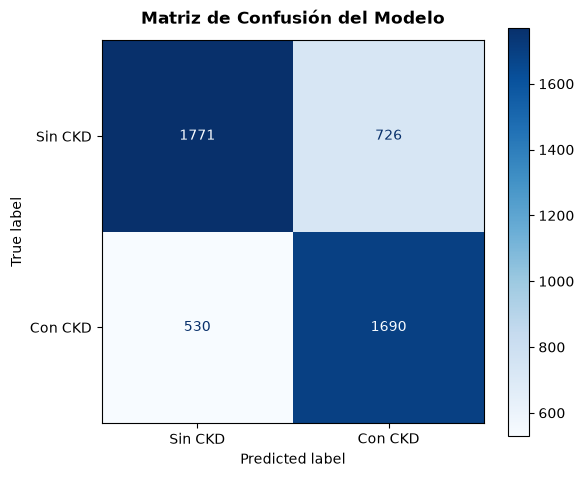

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Obtenemos las probabilidades predichas y asignamos la clase según el umbral 0.5
pred_prob = modelo.predict(X)
pred_class = (pred_prob >= 0.5).astype(int)

# Calculamos y graficamos la Matriz de Confusión
cm = confusion_matrix(y, pred_class)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Sin CKD", "Con CKD"])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax)
plt.title("Matriz de Confusión del Modelo", pad=12, fontweight="bold")
plt.tight_layout()
plt.show()

* **Accuracy (Exactitud) = 73.3%:**

## **Resultados**
Se ajustó un modelo de **Regresión Logística** utilizando la librería `statsmodels`.

#### 1. Evaluación Global del Modelo y Supuestos

- **Ajuste del Modelo (`LLR p-value` < 0.001):** El p-valor es prácticamente 0, lo que confirma que el modelo con el conjunto de predictores es estadísticamente superior a un modelo sin variables.
- **Bondad de Ajuste (`Pseudo R-squared` = 0.2276):** El modelo explica aproximadamente el 22.8% de la variabilidad en la probabilidad de presentar CKD, un valor muy respetable para los datos.
- **Multicolinealidad:** Al verificar la matriz de correlaciones previa, ninguna variable superó el umbral de $|r| > 0.7$, garantizando la independencia del modelo.

---

Inferencia y Significancia Estadísticas ($p < 0.05$)

#### Variables Significativas
Analizando la tabla de regresión (columna `P>|z|`), identificamos las variables que tienen un vínculo estadísticamente significativo con la presencia de CKD:

1. **Edad (`age`) — $\beta = 0.0717$, $p < 0.001$:**
   * **Efecto positivo y altamente significativo.** A mayor edad, se incrementa significativamente el riesgo de presentar CKD, siendo la variable con mayor estadístico de prueba ($z = 28.497$).
2. **Presión Arterial Sistólica (`bp_systolic`) — $\beta = 0.0091$, $p < 0.001$:**
   * **Efecto positivo y significativo.** Manteniendo constantes el resto de las variables (como edad e ingresos), un incremento en la presión arterial sistólica aumenta de forma independiente la probabilidad de diagnóstico de CKD ($z = 4.376$).
3. **Índice de Masa Corporal (`bmi`) — $\beta = 0.0143$, $p = 0.004$:**
   * **Efecto positivo y significativo.** Un mayor BMI se asocia a un leve incremento en la probabilidad de CKD ($z = 2.874$).

#### Variables NO Significativas ($p \ge 0.05$)
- **Nivel Socioeconómico (`poverty_income_ratio`, $p = 0.223$):** No muestra un efecto directo significativo al estar controlado por las variables clínicas.
- **Sexo (`gender_Male`, $p = 0.964$):** No existen diferencias estadísticamente significativas entre hombres y mujeres en la presencia de CKD bajo este modelo.
- **Tabaquismo (`ever_smoked_2.0`, $p = 0.971$):** En esta muestra multivariada, haber fumado no aportó una diferencia significativa.
- **Diabetes (`diabetes_diagnosed`):** Las categorías de no diabético ($2.0$, $p = 0.304$) y borderline ($3.0$, $p = 0.090$) no mostraron diferencias estadísticamente significativas respecto a la categoría de referencia (diabéticos diagnosticados $1.0$).

##### **Matriz de Confusión**
- Evalúa la capacidad del modelo como clasificador usando un umbral de decisión estándar de $0.5$.
- Muestra el balance entre verdaderos positivos (1690 casos con CKD detectados), verdaderos negativos (1771 pacientes sanos clasificados correctamente) y los errores de clasificación (726 falsos positivos y 530 falsos negativos).

### **Conclusión** 
La hipótesis se confirma **parcialmente**: existe un vínculo directo y estadísticamente significativo entre la **edad, la presión arterial sistólica y el BMI** con la probabilidad de padecer CKD.
Mientras que el nivel socioeconómico, el sexo y el tabaquismo no aportan un efecto independiente significativo en presencia de los factores de riesgo biológicos principales.

---

## Hipotesis Multivariada 2. "Los indicadores de salud física (como el peso y la presión arterial) y los marcadores de análisis de laboratorio (como la función de los riñones) se agrupan en patrones comunes que nos permiten ver qué variables se mueven juntas en la población."

En el ámbito de la salud, comprender cómo interactúan las variables físicas y los analisis de laboratorio permite identificar tempranamente perfiles de riesgo. Esto es clave para optimizar recursos de diagnóstico y diseñar intervenciones preventivas orientadas a las patologías más asociadas en la población.

**Usamos Componentes Principales (PCA)** Dado que contamos con múltiples variables cuantitativas que miden distintos aspectos clínicos (como la función renal, la presión arterial y la composición corporal), el PCA nos sirve como una herramienta multivariada de interdependencia. Su propósito no es predecir un resultado aislado, sino comprimir la dimensionalidad y revelarnos visualmente cómo se agrupan e interrelacionan estos factores biológicos en un espacio reducido.

Vamos a aplicar **PCA**, antes hacemos una estandarización ($Z$-score) sobre las 7 variables cuantitativas continuas para identificar cómo se agrupan e interrelacionan en la población. Ademas vamos a ver tambien cuantos componentes principales nos conviene usar.

Varianza explicada por PC1: 41.63%
Varianza explicada por PC2: 16.69%
Varianza acumulada (PC1 + PC2): 58.31%


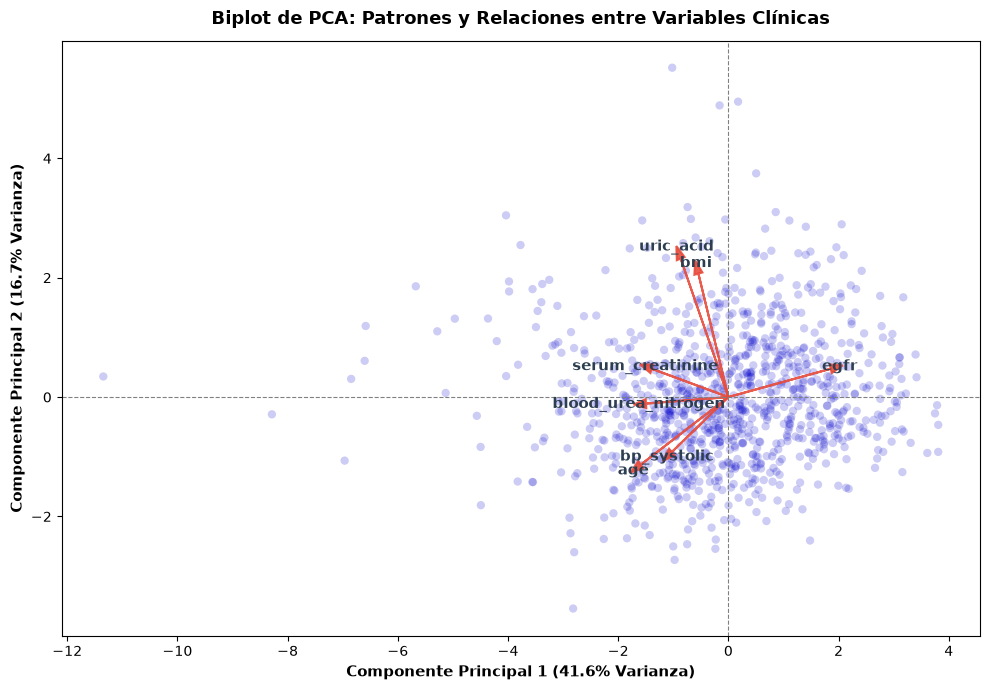

In [35]:
# PREPARACIÓN DE DATOS
# Seleccionamos solo variables cuantitativas continuas relevantes
cols_pca = [
    "age", 
    "bmi", 
    "bp_systolic", 
    "serum_creatinine", 
    "blood_urea_nitrogen", 
    "uric_acid", 
    "egfr"
]

# Limpiamos nulos en estas columnas
df_pca = df.dropna(subset=cols_pca).copy()

# ESTANDARIZACIÓN (Z-Score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_pca[cols_pca])

# AJUSTE DE PCA (2 Componentes para visualizar bien)
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_scaled)

# Porcentaje de varianza explicada. Aca lo hicimos con 2 componentes, pero mas abajo hacemos una tabla con mas, y con un elbow plot
var_explicada = pca.explained_variance_ratio_ * 100
print(f"Varianza explicada por PC1: {var_explicada[0]:.2f}%")
print(f"Varianza explicada por PC2: {var_explicada[1]:.2f}%")
print(f"Varianza acumulada (PC1 + PC2): {sum(var_explicada):.2f}%")

# BIPLOT (muestras y vectores de variables)
fig, ax = plt.subplots(figsize=(10, 7))

# Graficamos solo una muestra de los puntos para evitar que se sature visualmente
# Seleccionamos una muestra aleatoria de 1000 puntos del total del dataset. Se hace para evitar que el gráfico se sature
df_sample_idx = np.random.choice(componentes.shape[0], size=1000, replace=False)
ax.scatter(
    componentes[df_sample_idx, 0], 
    componentes[df_sample_idx, 1], 
    alpha=0.2, 
    c="#0000CC", 
    edgecolors="none"
)

# aca se dibujan los vectores de las variables
coefs = pca.components_
escala_flechas = 3.5

for i, feature in enumerate(cols_pca):
    ax.arrow(
        0, 0, 
        coefs[0, i] * escala_flechas, 
        coefs[1, i] * escala_flechas, 
        color="#e74c3c", 
        alpha=0.9, 
        head_width=0.15, 
        lw=1.5
    )
    ax.text(
        coefs[0, i] * (escala_flechas + 0.3), 
        coefs[1, i] * (escala_flechas + 0.3), 
        feature, 
        color="#2c3e50", 
        ha="center", 
        va="center", 
        fontsize=11, 
        fontweight="bold"
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel(f"Componente Principal 1 ({var_explicada[0]:.1f}% Varianza)", fontsize=11, fontweight="bold")
ax.set_ylabel(f"Componente Principal 2 ({var_explicada[1]:.1f}% Varianza)", fontsize=11, fontweight="bold")
ax.set_title("Biplot de PCA: Patrones y Relaciones entre Variables Clínicas", fontsize=13, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

TABLA DE VARIANZA EXPLICADA
Componente  Varianza Explicada (%)  Varianza Acumulada (%)
       PC1                   41.63                   41.63
       PC2                   16.69                   58.31
       PC3                   15.19                   73.51
       PC4                   10.78                   84.29
       PC5                    7.51                   91.80
       PC6                    6.40                   98.20
       PC7                    1.80                  100.00


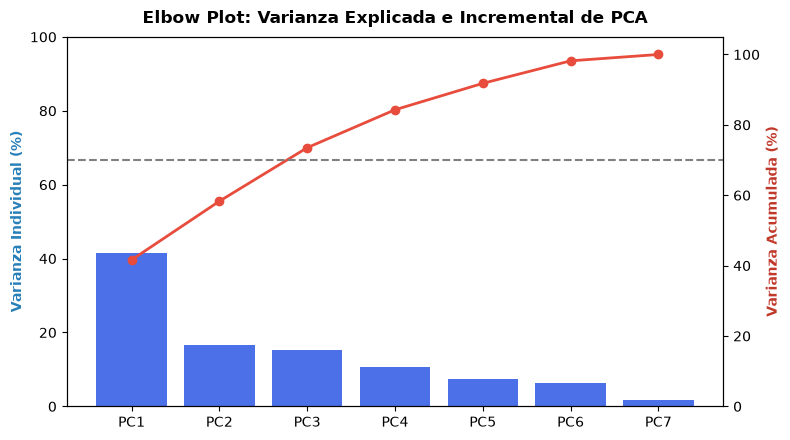

In [39]:
# Ajustamos PCA completo para las 7 componentes
pca_full = PCA(n_components=len(cols_pca)).fit(X_scaled)
var_exp = pca_full.explained_variance_ratio_ * 100
var_cum = np.cumsum(var_exp)

# hacemos una tabla de resumen
tabla_pca = pd.DataFrame({
    "Componente": [f"PC{i+1}" for i in range(len(cols_pca))],
    "Varianza Explicada (%)": np.round(var_exp, 2),
    "Varianza Acumulada (%)": np.round(var_cum, 2)
})

print("TABLA DE VARIANZA EXPLICADA")
print(tabla_pca.to_string(index=False))

# Graficamos el Elbow Plot
fig, ax1 = plt.subplots(figsize=(8, 4.5))

# Barras de varianza individual
ax1.bar(tabla_pca["Componente"], tabla_pca["Varianza Explicada (%)"], color="#0033dd", alpha=0.7, label="Varianza Individual (%)")
ax1.set_ylabel("Varianza Individual (%)", color="#2980b9", fontweight="bold")
ax1.set_ylim(0, 100)

# Línea de varianza acumulada
ax2 = ax1.twinx()
ax2.plot(tabla_pca["Componente"], tabla_pca["Varianza Acumulada (%)"], color="#e74c3c", marker="o", linewidth=2, label="Acumulada (%)")
ax2.axhline(70, color="gray", linestyle="--", linewidth=1.5, label="Umbral 70%")
ax2.set_ylabel("Varianza Acumulada (%)", color="#c0392b", fontweight="bold")
ax2.set_ylim(0, 105)

plt.title("Elbow Plot: Varianza Explicada e Incremental de PCA", fontweight="bold", pad=10)
fig.tight_layout()
plt.show()

### **Resultados**
**Análisis de Componentes Principales (PCA)**

#### Varianza Explicada
* **Componente Principal 1 (PC1):** Explica el **41.63%** de la variabilidad total.
* **Componente Principal 2 (PC2):** Explica el **16.69%** de la variabilidad total.
* **Varianza Acumulada (PC1 + PC2):** **58.31%**.

**Aclaración:** La varianza explicada por las dos primeras componentes se sitúa por debajo de lo recomendado (70%) para una representación en 2 dimensiones. Esto indica la presencia de patrones no lineales o una alta dimensionalidad en los datos. Podriamos sumar mas componentes principales, en el segundo grafico **Elbow Plot** vemos que si agregamos un tercer componente podriamos tener un **73.51%** de la variabilidad acumulada total, pero esto tiene consecuencias, dificulta el entendimiento y hace muy dificil graficar la relación. Ademas esto solo para llegar casi justo a lo recomendado que es 70%. Para llegar a **84.29%** deberiamos tener 4 componentes principales, imposible de graficar.

---

#### Interpretación del Biplot (Patrones entre las variables)

Al analizar la orientación y dirección de los vectores (flechas en el gráfico), se observan tres agrupaciones clínicas definidas:

 **Deterioro Renal (Eje Horizontal - PC1):** 
   * La flecha de `egfr` (filtrado glomerular) se orienta en dirección opuesta ($180^\circ$) respecto a `serum_creatinine` y `blood_urea_nitrogen`.
   * Esto refleja la relación biológica logica: a menor capacidad de filtrado renal, mayor es la concentración de productos de desecho en sangre.
 **Perfil Metabólico (Eje Vertical Superior - PC2):**
   * Los vectores de `bmi` (índice de masa corporal) y `uric_acid` (ácido úrico) presentan un ángulo muy pequeño entre sí, indicando una correlación positiva directa entre el exceso de peso y los niveles de ácido úrico.
 **Cardiovascular / Edad (Eje Vertical Inferior - PC2):**
   * Las variables `age` (edad) y `bp_systolic` (presión arterial sistólica) apuntan en una misma dirección, evidenciando que el incremento en la presión arterial se encuentra muy ligado al envejecimiento.

---

### **Conclusión**
El PCA confirma de manera visual la existencia de tres patrones o dimensiones biológicas independientes en los datos: la **función de filtrado renal**, el **componente corporal** y el **factor de envejecimiento/presión arterial**. Aunque la proyección en 2 dimensiones solo tiene el 58.31% de la información, valida que los marcadores clínicos se mueven conjuntamente en grupos bien delimitados y mediante el Biplot, se pueden ver estas relaciones analizando el angulo entre vectores.